# Sección 3 · Análisis exploratorio para series de tiempo

El análisis exploratorio original eran histogramas y tortas: describía **cuánto** hay. Para pronosticar necesitamos saber **cómo se mueve en el tiempo**. Una serie de tiempo se puede pensar como la suma de cuatro piezas:

$$\text{energía}_t = \text{nivel} + \text{tendencia} + \text{estacionalidad} + \text{choques}$$

| Pieza | Pregunta | Para qué nos sirve |
|---|---|---|
| Nivel | ¿Cuánto consume cada localidad? | Escala del pronóstico |
| Tendencia | ¿Crece o decrece año a año? | Variables de tendencia / crecimiento |
| Estacionalidad | ¿Hay meses que siempre son más altos? | Variable "mes del año"; ver si sirve el modelo ingenuo estacional |
| Choques | ¿Cuánto ruido hay? ¿Los choques duran o se corrigen solos? | Qué rezagos usar y qué precisión esperar |

Trabajamos con las **78 localidades elegibles** de la Sección 2.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

FIG = Path("../figuras")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
AZUL, ROJO, GRIS = "#3b6ea5", "#c0392b", "#888888"

p = pd.read_csv("../datos/processed/energia_limpia.csv", parse_dates=["fecha"])
p = p[p.elegible].sort_values(["id_loc", "fecha"]).copy()
p["dias"] = p.fecha.dt.days_in_month
print(p.id_loc.nunique(), "localidades |", len(p), "filas |", p.e_activa.notna().sum(), "meses con energía")

78 localidades | 3071 filas | 2788 meses con energía


## 3.1 Primer descubrimiento: febrero no consume menos, tiene menos días

Si comparamos el consumo de cada mes, febrero sale ~7 % más bajo. ¿Hay algo estacional en febrero? Antes de concluirlo, hay una explicación más simple: **febrero tiene 28 días y marzo 31** (10 % más).

Para comparar meses de forma justa, dividimos la energía por los días del mes: **kWh/día**.

Para poder mezclar localidades de tamaños muy distintos, cada valor se divide por el promedio de su localidad (fuera del periodo COVID). Así un **índice = 1,05** significa "5 % por encima de lo normal en esa localidad".

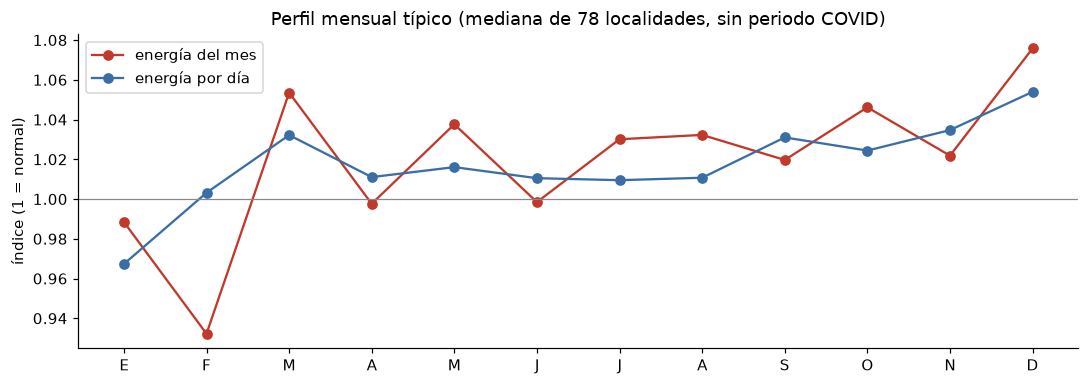

mes,1,2,3,4,5,6,7,8,9,10,11,12
kWh/mes,0.988,0.932,1.054,0.998,1.038,0.998,1.030,1.032,1.020,1.046,1.022,1.076
kWh/día,0.967,1.003,1.032,1.011,1.016,1.011,1.009,1.011,1.031,1.024,1.035,1.054


In [2]:
p["e_dia"] = p.e_activa / p.dias
base_mes = p[p.covid == 0].groupby("id_loc").e_activa.mean()
base_dia = p[p.covid == 0].groupby("id_loc").e_dia.mean()
p["idx_mes"] = p.e_activa / p.id_loc.map(base_mes)
p["idx_dia"] = p.e_dia / p.id_loc.map(base_dia)

nc = p[(p.covid == 0) & ~p.sin_servicio]
perfil = pd.DataFrame({"kWh/mes": nc.groupby("mes").idx_mes.median(), "kWh/día": nc.groupby("mes").idx_dia.median()})
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(perfil.index, perfil["kWh/mes"], marker="o", color=ROJO, label="energía del mes")
ax.plot(perfil.index, perfil["kWh/día"], marker="o", color=AZUL, label="energía por día")
ax.axhline(1, color=GRIS, lw=0.8)
ax.set_xticks(range(1, 13)); ax.set_xticklabels(["E","F","M","A","M","J","J","A","S","O","N","D"])
ax.set(title="Perfil mensual típico (mediana de 78 localidades, sin periodo COVID)", ylabel="índice (1 = normal)")
ax.legend(); fig.tight_layout(); fig.savefig(FIG / "s3_perfil_mensual.png"); plt.show()
perfil.T.round(3)

**Resultado:** con kWh/día, la caída de febrero **desaparece** (de 0,93 a 1,00). No era estacionalidad: era el calendario.

**Decisión para el modelo:** el objetivo será la **energía por día** (`e_dia`). Para entregar el pronóstico mensual se multiplica por los días del mes. Así el modelo no tiene que "aprender" algo que ya sabemos con certeza.

Fuera de eso, el perfil es casi plano: los meses se mueven entre −3 % y +5 %. Diciembre sale algo más alto (fiestas, regreso de personas a sus pueblos), pero el efecto es pequeño.

## 3.2 Estacionalidad: ¿un mes se parece al mismo mes del año anterior?

Si hubiera estacionalidad fuerte, el modelo ingenuo estacional ("igual que hace 12 meses") sería bueno. Lo medimos con la **autocorrelación**: la correlación de la serie consigo misma desplazada *L* meses. Usamos el logaritmo de kWh/día, restando el promedio de cada localidad para comparar solo las **variaciones** y no los tamaños.

IntervalIndex([(2876.134, 8189.709], (8189.709, 48108.761],
               (48108.761, 16008727.263]],
              dtype='interval[float64, right]')


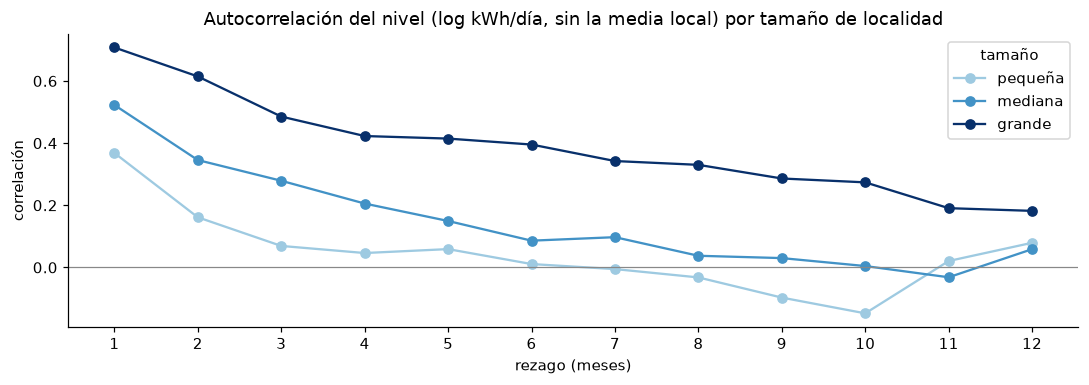

,1,2,3,4,5,6,7,8,9,10,11,12
pequeña,0.37,0.16,0.07,0.05,0.06,0.01,-0.01,-0.03,-0.10,-0.15,0.02,0.08
mediana,0.52,0.35,0.28,0.21,0.15,0.09,0.10,0.04,0.03,0.00,-0.03,0.06
grande,0.71,0.61,0.49,0.42,0.41,0.40,0.34,0.33,0.29,0.27,0.19,0.18


In [3]:
ok = p.e_activa > 5                       # los meses sin servicio no tienen logaritmo
p["led"] = np.where(ok, np.log(p.e_dia.where(ok)), np.nan)
p["dm"] = p.led - p.groupby("id_loc").led.transform("mean")

media = p.groupby("id_loc").e_activa.mean()
p["tamano"] = p.id_loc.map(pd.qcut(media, 3, labels=["pequeña", "mediana", "grande"]))
# Grupos por tercios: pequeña < ~8.200 kWh/mes · mediana 8.200–48.000 · grande > 48.000
print(pd.qcut(media, 3).cat.categories)

lags = range(1, 13)
acf = {g: [s.dm.corr(s.groupby("id_loc").dm.shift(L)) for L in lags] for g, s in p.groupby("tamano", observed=True)}
fig, ax = plt.subplots(figsize=(10, 3.6))
for (g, v), c in zip(acf.items(), ["#9ecae1", "#4292c6", "#08306b"]):
    ax.plot(list(lags), v, marker="o", color=c, label=g)
ax.axhline(0, color=GRIS, lw=0.8); ax.set_xticks(list(lags))
ax.set(title="Autocorrelación del nivel (log kWh/día, sin la media local) por tamaño de localidad",
       xlabel="rezago (meses)", ylabel="correlación"); ax.legend(title="tamaño")
fig.tight_layout(); fig.savefig(FIG / "s3_autocorrelacion.png"); plt.show()
pd.DataFrame(acf, index=list(lags)).T.round(2)

**Cómo leer la gráfica:**
- **Rezago 1:** cuánto se parece este mes al anterior. En las localidades **grandes** es alto: la serie es "persistente".
- **Caída con el rezago:** el parecido se pierde con los meses. Es lo esperable con una tendencia suave más choques.
- **Rezago 12:** **no hay pico**. Un mes no se parece especialmente al mismo mes del año anterior. Esto confirma 3.1: la estacionalidad es débil.

**Consecuencias:**
1. El modelo ingenuo estacional (hace 12 meses) probablemente será **peor** que el ingenuo simple (mes anterior). Igual lo usamos como referencia, porque es el estándar en la literatura.
2. Los **rezagos recientes (1–3 meses)** son la información más valiosa.
3. Un **SARIMA** (con componente estacional) tiene poco que aprender en la parte estacional y además pocos datos por serie. Otro argumento a favor del modelo global.

## 3.3 Tendencia: ¿las ZNI consumen más cada año?

Medimos el **crecimiento interanual**: cada mes comparado con el mismo mes del año anterior (en logaritmo, que es aproximadamente un %). Usamos la mediana entre localidades para que no domine San Andrés.

Crecimiento interanual típico (mediana entre localidades):
anio
2021    7.4 %
2022    3.0 %
2023    3.2 %
Name: yoy, dtype: str


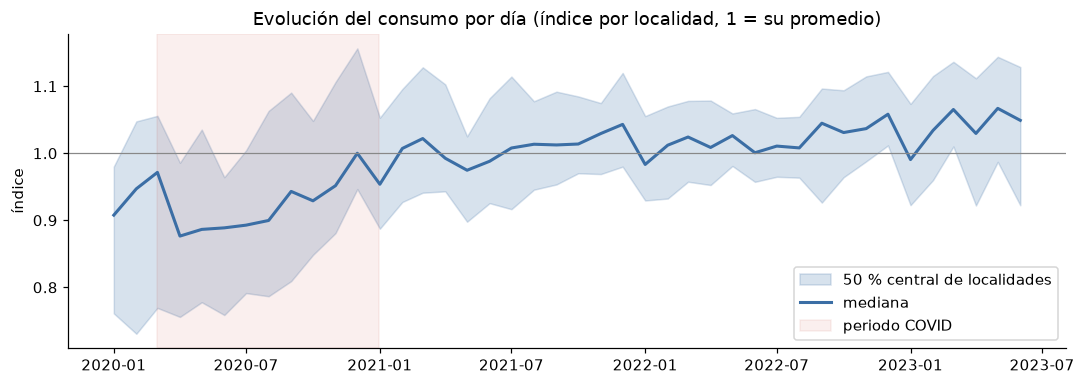

In [4]:
p["yoy"] = p.led - p.groupby("id_loc").led.shift(12)
crec = p.groupby("anio").yoy.median().dropna()
print("Crecimiento interanual típico (mediana entre localidades):")
print((np.expm1(crec) * 100).round(1).astype(str) + " %")

serie = p[~p.sin_servicio].groupby("fecha").idx_dia.agg(["median", lambda s: s.quantile(.25), lambda s: s.quantile(.75)])
serie.columns = ["mediana", "q25", "q75"]
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.fill_between(serie.index, serie.q25, serie.q75, color=AZUL, alpha=0.2, label="50 % central de localidades")
ax.plot(serie.index, serie.mediana, color=AZUL, lw=2, label="mediana")
ax.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2020-12-31"), color=ROJO, alpha=0.08, label="periodo COVID")
ax.axhline(1, color=GRIS, lw=0.8)
ax.set(title="Evolución del consumo por día (índice por localidad, 1 = su promedio)", ylabel="índice"); ax.legend(loc="lower right")
fig.tight_layout(); fig.savefig(FIG / "s3_tendencia.png"); plt.show()

**Resultado:** la localidad típica de las ZNI consume **más cada año**: ~+7 % en 2021 (incluye el rebote después del COVID) y ~+3 % anual en 2022 y 2023. Es una tendencia **suave y positiva**.

**Consecuencia para el modelo:** el pronóstico debe poder seguir esta tendencia. Los modelos de árboles (Random Forest, LightGBM) **no extrapolan**: nunca predicen un valor mayor que los que vieron al entrenar. Por eso conviene modelar el **cambio** respecto al nivel reciente (por ejemplo, el log del cociente entre este mes y el promedio de los últimos 3) en lugar del valor absoluto. Lo implementamos en la Sección 4.

## 3.4 Choques: ¿cuánto ruido hay y cuánto dura?

Miramos el **cambio mensual** (diferencia del log kWh/día, ≈ % de cambio respecto al mes anterior):
- Su **desviación estándar** dice qué tan volátil es la localidad.
- La **correlación de un cambio con el siguiente** dice si los choques **persisten** (positiva) o **se revierten** (negativa).

Volatilidad mensual típica (desv. estándar del cambio, ≈ %):


,volatilidad %
tamano,
pequeña,22.3
mediana,23.5
grande,6.6


Correlación entre el cambio de un mes y el del mes siguiente: -0.30


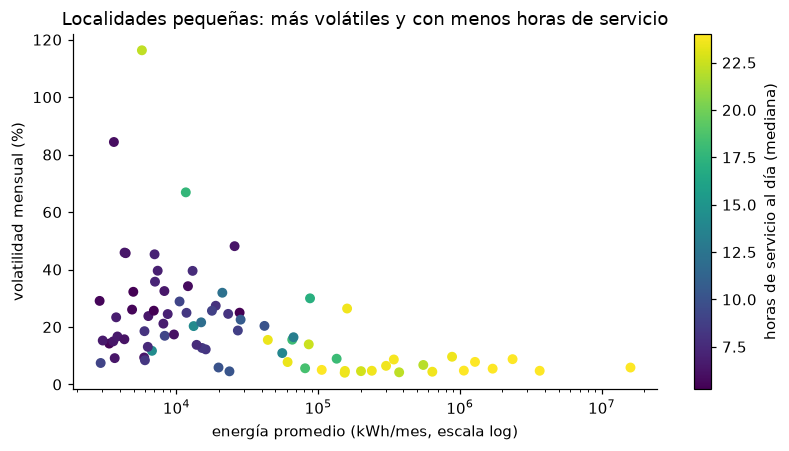

In [5]:
p["d1"] = p.groupby("id_loc").led.diff()
vol = p.groupby("id_loc").agg(media=("e_activa", "mean"), volatilidad=("d1", "std"), tamano=("tamano", "first"),
                              horas=("horas_dia", "median"))
print("Volatilidad mensual típica (desv. estándar del cambio, ≈ %):")
display((vol.groupby("tamano", observed=True).volatilidad.median() * 100).round(1).to_frame("volatilidad %"))
rev = p.d1.corr(p.groupby("id_loc").d1.shift(1))
print(f"Correlación entre el cambio de un mes y el del mes siguiente: {rev:.2f}")

fig, ax = plt.subplots(figsize=(7.5, 4.2))
sc = ax.scatter(vol.media, vol.volatilidad * 100, c=vol.horas, cmap="viridis", s=30)
ax.set_xscale("log"); fig.colorbar(sc, label="horas de servicio al día (mediana)")
ax.set(title="Localidades pequeñas: más volátiles y con menos horas de servicio",
       xlabel="energía promedio (kWh/mes, escala log)", ylabel="volatilidad mensual (%)")
fig.tight_layout(); fig.savefig(FIG / "s3_volatilidad.png"); plt.show()

**Dos hallazgos clave:**

1. **El tamaño define la predictibilidad.** Las localidades grandes, con servicio de 24 h, varían ~7 % de un mes a otro. Las pequeñas y medianas, con servicio de pocas horas, **más de 20 %**. Hay que esperar pronósticos mucho menos precisos para las veredas, y conviene reportar los errores **por grupo de tamaño**.

2. **Los choques se revierten** (correlación negativa entre cambios consecutivos). Cuando un mes cae (una falla, falta de combustible), el siguiente tiende a **recuperarse**. Por eso el modelo ingenuo "igual que el mes pasado" falla justo después de un choque. Usar el **promedio de los últimos 3 meses** como referencia debería ser más robusto. Lo probaremos.

## 3.5 ¿Demanda o oferta? El papel de las horas de servicio

Esta es quizás la observación más importante para interpretar el proyecto. En las ZNI pequeñas, el servicio **no** es de 24 horas. Si la planta opera 6 horas en lugar de 8, la energía cae, **aunque la gente quiera consumir lo mismo**.

¿Cuánto del cambio mensual de energía se explica por el cambio en horas de servicio **del mismo mes**?

,servicio limitado (<23 h),servicio ~24 h
localidades,61.00,17.00
"corr(cambio energía, cambio horas)",0.81,0.75
% meses en que las horas cambian > 1 h,32.80,7.90
"volatilidad energía, todos los meses (%)",29.80,9.50
"volatilidad energía, horas estables (%)",8.10,5.70


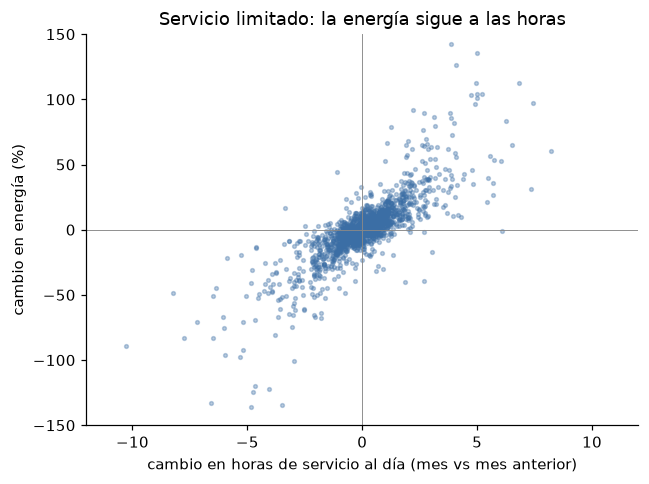

In [6]:
p["dh"] = p.groupby("id_loc").horas_dia.diff()
limitadas = p.id_loc.map(vol.horas < 23)
filas = {}
for nombre, m in [("servicio limitado (<23 h)", limitadas), ("servicio ~24 h", ~limitadas)]:
    s = p[m].dropna(subset=["d1", "dh"])
    cambia = s.dh.abs() > 1
    filas[nombre] = {"localidades": s.id_loc.nunique(),
                     "corr(cambio energía, cambio horas)": round(s.d1.corr(s.dh), 2),
                     "% meses en que las horas cambian > 1 h": round(100 * cambia.mean(), 1),
                     "volatilidad energía, todos los meses (%)": round(100 * s.d1.std(), 1),
                     "volatilidad energía, horas estables (%)": round(100 * s[~cambia].d1.std(), 1)}
display(pd.DataFrame(filas))

fig, ax = plt.subplots(figsize=(6, 4.5))
s = p[limitadas]
ax.scatter(s.dh, s.d1 * 100, s=6, alpha=0.35, color=AZUL)
ax.set(xlim=(-12, 12), ylim=(-150, 150), xlabel="cambio en horas de servicio al día (mes vs mes anterior)",
       ylabel="cambio en energía (%)", title="Servicio limitado: la energía sigue a las horas")
ax.axhline(0, color=GRIS, lw=0.6); ax.axvline(0, color=GRIS, lw=0.6)
fig.tight_layout(); fig.savefig(FIG / "s3_horas_vs_energia.png"); plt.show()

**Interpretación:**
- En **ambos** grupos, cuando cambian las horas de servicio, la energía las sigue (correlación alta). Lo que medimos es la **energía servida**, que es **demanda limitada por la oferta**.
- La diferencia está en la **frecuencia**: en las localidades con servicio limitado las horas cambian más de 1 hora en **1 de cada 3 meses**. En las de 24 h, en menos de 1 de cada 10 (y suele ser por una falla).
- La prueba más fuerte: si miramos solo los meses en que las horas **no** cambiaron, la volatilidad de las localidades con servicio limitado **baja de ~30 % a ~8 %**, casi el nivel de las grandes. **La mayor parte del "ruido" de las veredas viene de la operación del sistema, no del consumo de la gente.**

**Consecuencias:**
- Para tu presentación es un punto fuerte: en las ZNI, pronosticar "consumo" es en buena parte pronosticar **cuántas horas habrá servicio**, que depende de combustible, mantenimiento y logística.
- Las horas del **mismo mes** no se pueden usar (Sección 1: fuga). Pero las horas de los **meses anteriores** y su tendencia sí, y entrarán como variables rezagadas.
- Esto explica por qué el error será mayor en las localidades pequeñas: el modelo no puede anticipar una falla de la planta.

## 3.6 Efecto real del COVID-19

Comparamos abril–diciembre de 2020 contra los mismos meses de 2021 (kWh/día) en cada localidad. Un cociente de 0,70 significa que en 2020 se consumió 30 % menos.

In [7]:
c = (p[p.anio.isin([2020, 2021]) & p.mes.between(4, 12)]
     .pivot_table(index="id_loc", columns="anio", values="e_dia", aggfunc="mean").dropna())
c["cociente"] = c[2020] / c[2021]
c["nombre"] = p.groupby("id_loc").nombre_corto.first()
a2020 = p[p.anio == 2020].groupby("id_loc")
c["meses_falla_2020"] = a2020.sin_servicio.sum() + a2020.servicio_parcial.sum()
print(f"Cociente típico 2020/2021 (mediana): {c.cociente.median():.2f}  →  {len(c)} localidades comparables")
c.sort_values("cociente").head(8)[["nombre", 2020, 2021, "cociente", "meses_falla_2020"]].round(2)

Cociente típico 2020/2021 (mediana): 0.93  →  78 localidades comparables


anio,nombre,2020,2021,cociente,meses_falla_2020
id_loc,,,,,
19809009,Santa Rosa De Saija,4.08,144.30,0.03,2
19809026,Los Brazos,7.94,224.56,0.04,1
27001029,Tagachi,152.78,294.87,0.52,1
44847012,Nazareth,1017.34,1883.90,0.54,0
13001017,Santa Cruz Del Islote,339.57,589.70,0.58,0
27800005,Titumate,348.69,586.78,0.59,0
94343000,Barrancominas,1307.85,1976.81,0.66,0
88001000,San Andrés,386058.47,564305.58,0.68,0


**Resultado:** la localidad típica consumió **solo ~7 % menos** en 2020. **El COVID no fue un choque general en las ZNI**. El caso más claro es **San Andrés (−32 %)**, cuya economía depende del turismo, que se cerró.

Hay que ser cuidadosos con el resto de la lista:
- Los cocientes más extremos (Santa Rosa de Saija, Los Brazos) **no son COVID**: esas localidades tuvieron meses sin servicio o con servicio parcial en 2020 (columna `meses_falla_2020`).
- Otras con caídas fuertes (Tagachí, Nazareth, Santa Cruz del Islote) pueden mezclar el efecto COVID con problemas de suministro. **Con estos datos no se puede separar una cosa de la otra.** Así se debe decir en la presentación, en lugar de atribuirlo todo al COVID.

**Decisión para el modelo:** no se borra 2020. Se usa la variable `covid` y el modelo aprende **por sí mismo** cuánto pesó en cada tipo de localidad. Al evaluar sobre 2022–2023 (sin COVID), su presencia en el entrenamiento no contamina la evaluación.

## 3.7 Conclusiones: del análisis a las variables del modelo

| Hallazgo | Evidencia | Decisión para la Sección 4 |
|---|---|---|
| Febrero "bajo" es efecto calendario | El perfil se aplana con kWh/día | **Objetivo = kWh/día** (luego × días del mes) |
| Estacionalidad débil | Sin pico en rezago 12; perfil ±3–5 % | `mes` como variable, pero con poco peso esperado |
| Persistencia de corto plazo | Autocorrelación alta en rezagos 1–3 (grandes) | Rezagos 1, 2, 3 y promedio de 3 meses |
| Tendencia suave positiva (~3 %/año) | Crecimiento interanual | Modelar el **cambio** respecto al nivel reciente (los árboles no extrapolan) |
| Choques que se revierten | Correlación negativa entre cambios consecutivos | Referencia "promedio 3 meses"; variable "¿hubo choque el mes pasado?" |
| Volatilidad según tamaño (7 % vs 20 %+) | Gráfica de volatilidad | Evaluar **por grupo de tamaño**; métricas relativas |
| Energía limitada por la oferta | Con horas estables, la volatilidad de las veredas baja de ~30 % a ~8 % | Horas de servicio **rezagadas** como variables; esperar errores altos en localidades con servicio limitado |
| COVID: efecto típico pequeño, fuerte en San Andrés | San Andrés −32 %, típica −7 % | Variable `covid`; evaluar solo en 2022–2023 |

**Referencias que se comparan en la Sección 4:**
1. Ingenuo: igual que el mes anterior
2. Ingenuo estacional: igual que hace 12 meses
3. Promedio móvil: promedio de los últimos 3 meses

In [8]:
p.to_csv("../datos/processed/energia_eda.csv", index=False)
print("Guardado con las variables nuevas: e_dia, idx_dia, tamano, led, d1, dh")

Guardado con las variables nuevas: e_dia, idx_dia, tamano, led, d1, dh
